# Práctica: Bit Rate Control

### Experimento 1. Which data-ordering performs better?
**Enunciado:** Determine empirically which ordering of the chunk data is the most efficient from a lossless data compression point of view (the smaller the bit-rates, the higher the compression). Use the audio sequence you want. Notice that using different audio files you could obtain different results.

#### Comando de instalación de librerías
```pip install soundfile librosa matplotlib numpy```

### Código del experimento

In [ ]:
import os
import csv
import zlib
import numpy as np
import librosa

AUDIO_FILES = [
    "./data/FrancoBattiato_LombraDellaLuce.oga",
    "./data/VVV_InviernoNuclear.oga",
    "./data/Metallica_Orion.mp3",
    "./data/Bossfight - Nock Em - BOSSFIGHT.mp3",
]

CHUNK_SIZE = 1024  
MAX_DURATION = 30.0  
CSV_FILENAME = "resultados_ejercicio1.csv"

# Preparamos el archivo CSV
with open(CSV_FILENAME, mode='w', newline='', encoding='utf-8') as csv_file:
    writer = csv.writer(csv_file)
    writer.writerow([
        "Cancion", 
        "Duracion_Procesada_sec", 
        "Raw_Bytes", "Raw_Bitrate_kbps", 
        "Serial_Bytes", "Serial_Bitrate_kbps", 
        "Byteplanes2_Bytes", "Byteplanes2_Bitrate_kbps",
        "Mejor_Metodo"
    ])

print("=" * 70)
print(" PROCESANDO EJERCICIO 1 (PRIMEROS 30 SEGUNDOS POR CANCIÓN)")
print("=" * 70)

for file_path in AUDIO_FILES:
    if not os.path.exists(file_path):
        print(f"⚠️ Archivo no encontrado: {file_path}. Saltando...")
        continue
        
    print(f"Procesando (30s): {file_path}...")
    
    
    audio_signal, sr = librosa.load(file_path, sr=None, mono=False, duration=MAX_DURATION)
    
    if audio_signal.ndim == 1:
        audio_signal = np.vstack([audio_signal, audio_signal])

    pcm_data = (audio_signal * 32767).astype(np.int16).T
    total_samples = len(pcm_data)
    duration_sec = total_samples / sr
    num_chunks = total_samples // CHUNK_SIZE

    bytes_raw = 0
    bytes_serial = 0
    bytes_byteplanes2 = 0

    for i in range(num_chunks):
        chunk = pcm_data[i * CHUNK_SIZE : (i + 1) * CHUNK_SIZE]
        
        
        raw_b = chunk.tobytes()
        bytes_raw += len(zlib.compress(raw_b))
        
       
        left_ch = chunk[:, 0]
        right_ch = chunk[:, 1]
        serial_b = left_ch.tobytes() + right_ch.tobytes()
        bytes_serial += len(zlib.compress(serial_b))
        
        
        arr_uint8 = np.frombuffer(serial_b, dtype=np.uint8)
        lsb = arr_uint8[0::2].tobytes()
        msb = arr_uint8[1::2].tobytes()
        bytes_byteplanes2 += len(zlib.compress(msb)) + len(zlib.compress(lsb))

    
    bitrate_raw = (bytes_raw * 8) / duration_sec / 1000
    bitrate_serial = (bytes_serial * 8) / duration_sec / 1000
    bitrate_byteplanes2 = (bytes_byteplanes2 * 8) / duration_sec / 1000

    results_map = {
        "DEFLATE_raw": bitrate_raw,
        "DEFLATE_serial": bitrate_serial,
        "DEFLATE_byteplanes2": bitrate_byteplanes2
    }
    best_method = min(results_map, key=results_map.get)

    
    with open(CSV_FILENAME, mode='a', newline='', encoding='utf-8') as csv_file:
        writer = csv.writer(csv_file)
        writer.writerow([
            file_path,
            round(duration_sec, 2),
            bytes_raw, round(bitrate_raw, 2),
            bytes_serial, round(bitrate_serial, 2),
            bytes_byteplanes2, round(bitrate_byteplanes2, 2),
            best_method
        ])

print("\n" + "=" * 70)
print(f"¡Proceso completado! Archivo de salida: '{CSV_FILENAME}'.")
print("=" * 70)

 PROCESANDO EJERCICIO 1 (PRIMEROS 30 SEGUNDOS POR CANCIÓN)
Procesando (30s): ./data/FrancoBattiato_LombraDellaLuce.oga...
Procesando (30s): ./data/VVV_InviernoNuclear.oga...
Procesando (30s): ./data/Metallica_Orion.mp3...
Procesando (30s): ./data/Bossfight - Nock Em - BOSSFIGHT.mp3...

¡Proceso completado! Archivo de salida: 'resultados_ejercicio1.csv'.


**Que hemos hecho:** Hemos probado los cuatro audios proporcionados (FrancoBattiato, VVV, Metallica y Bossfight) para comparar que ordenacion de los datos comprime mejor con DEFLATE.

**Resultados:** Los datos procesados se guardan en `resultados_ejercicio1.csv`. Para cada audio se comparan DEFLATE_raw, DEFLATE_serial y DEFLATE_byteplanes2; el menor bit-rate representa la mejor compresion sin perdidas.


### Experimento 2. Which BR control algorithm shows the best RD (Rate/Distortion) curve?
**Enunciado:** Considering the RMSE (Root Mean Square Error) as a distortion measure between the sent and the received audio signal, for a concrete audio sequence, generate the RD curve considering a set of different simulated transmission environments (use tc or a any other similar tool). Remember that the X-axis must express bit-rate and the Y-axis, distortion.

### Código del experimento

(INFO) minimal: A minimal InterCom (no compression, no quantization, no transform, ... only provides a bidirectional (full-duplex) transmission of raw (hardware-playable) chunks. 
(INFO) minimal: chunk_time = 0.023219954648526078 seconds
(INFO) buffer: Over minimal, implements a random access buffer structure for hiding the jitter.
(INFO) buffer: buffering time = 150 miliseconds
(INFO) buffer: chunks to buffer = 7
(INFO) buffer: chunks_to_buffer = 7
(INFO) DEFLATE_raw: Compress each raw chunk using DEFLATE.
(INFO) DEFLATE_byteplanes3: Compress the least significant byte planes of the chunks using DEFLATE. The channels are consecutive (serialized). 3 code-streams (one per byte-plane) are generated.
(INFO) BR_control_no: No bit-rate control using quantization. In this module, no control has been implemented. Both channels are quantized using the same constant step size.
(INFO) BR_control_no: rate_control_period = 1000000000 seconds
(INFO) BR_control_no: (minimum) quantization_step_size =

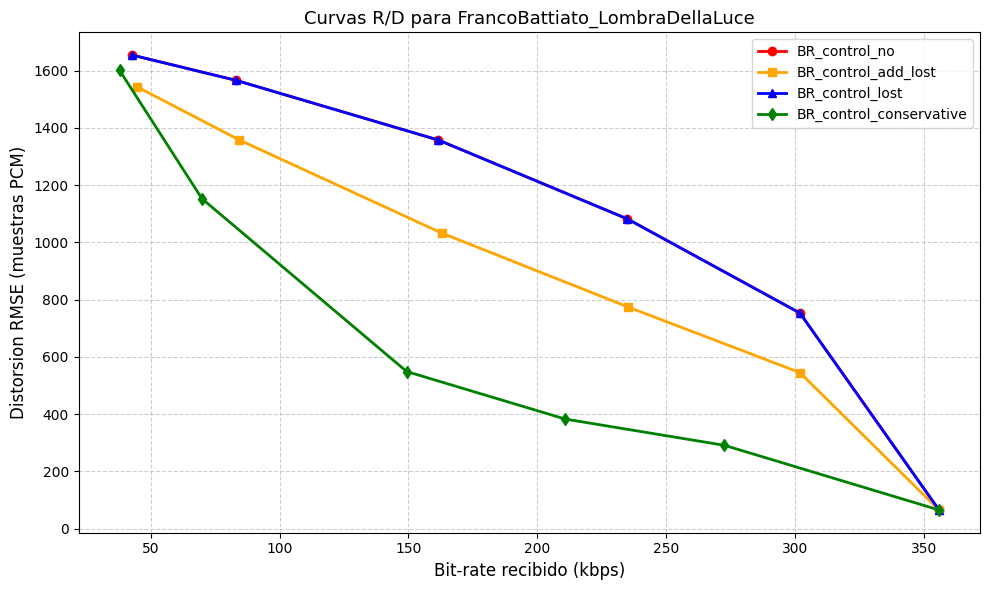

In [ ]:
import os
import sys
import numpy as np
import librosa
import matplotlib.pyplot as plt

sys.path.append("src")
import minimal
from BR_control_no import BR_Control_No
from BR_control_add_lost import BR_Control_Add_Lost
from BR_control_lost import BR_Control_Lost
from BR_control_conservative import BR_Control_Conservative


AUDIO_FILE = "./data/FrancoBattiato_LombraDellaLuce.oga"
MAX_DURATION = 30.0
CHUNK_SIZE = 1024

CAPACITIES_KBPS = [50, 100, 200, 300, 400, 600]
MIN_QSS = 128
MAX_QSS = 32768

ALGORITHM_CLASSES = {
    "BR_control_no": BR_Control_No,
    "BR_control_add_lost": BR_Control_Add_Lost,
    "BR_control_lost": BR_Control_Lost,
    "BR_control_conservative": BR_Control_Conservative,
}


minimal.args = minimal.parser.parse_args([])
minimal.args.filename = None
minimal.args.rate_control_period = 10**9
minimal.args.minimal_quantization_step_size = MIN_QSS

def update_qss(controller, algorithm, lost_chunks):
    """Aplica la regla de control definida en cada modulo BR_control."""
    if algorithm == "BR_control_add_lost":
        controller.quantization_step_size += lost_chunks - 1
    elif algorithm == "BR_control_lost":
        controller.quantization_step_size = lost_chunks - 1
    elif algorithm == "BR_control_conservative":
        if lost_chunks > 2:
            controller.quantization_step_size *= 2
        controller.quantization_step_size = int(controller.quantization_step_size / 1.1)
    controller.quantization_step_size = min(
        MAX_QSS,
        max(MIN_QSS, int(controller.quantization_step_size)),
    )

audio_signal, sample_rate = librosa.load(
    AUDIO_FILE, sr=None, mono=False, duration=MAX_DURATION
)
if audio_signal.ndim == 1:
    audio_signal = np.vstack((audio_signal, audio_signal))
pcm_data = (audio_signal * 32767).astype(np.int16).T
num_chunks = len(pcm_data) // CHUNK_SIZE
pcm_data = pcm_data[:num_chunks * CHUNK_SIZE]
duration_sec = len(pcm_data) / sample_rate
chunks_per_second = max(1, round(sample_rate / CHUNK_SIZE))

results = {name: [] for name in ALGORITHM_CLASSES}
for algorithm, algorithm_class in ALGORITHM_CLASSES.items():
    for scenario_index, capacity_kbps in enumerate(CAPACITIES_KBPS):
        minimal.args.listening_port = 42000 + scenario_index
        minimal.args.destination_port = minimal.args.listening_port
        controller = algorithm_class()
        reconstructed_chunks = []
        received_bytes = 0
        lost_in_second = 0
        bytes_in_second = 0
        second_capacity_bytes = capacity_kbps * 1000 / 8

        for chunk_index in range(num_chunks):
            if chunk_index > 0 and chunk_index % chunks_per_second == 0:
                update_qss(controller, algorithm, lost_in_second)
                lost_in_second = 0
                bytes_in_second = 0

            original_chunk = pcm_data[
                chunk_index * CHUNK_SIZE : (chunk_index + 1) * CHUNK_SIZE
            ]
            packed_chunk = controller.pack(chunk_index, original_chunk)


            if bytes_in_second + len(packed_chunk) <= second_capacity_bytes:
                bytes_in_second += len(packed_chunk)
                received_bytes += len(packed_chunk)
                _, reconstructed_chunk = controller.unpack(packed_chunk)
                reconstructed_chunks.append(reconstructed_chunk.astype(np.int32))
            else:
                reconstructed_chunks.append(
                    np.zeros_like(original_chunk, dtype=np.int32)
                )
                lost_in_second += 1

        controller.sock.close()
        reconstructed_signal = np.vstack(reconstructed_chunks).astype(np.float64)
        original_signal = pcm_data.astype(np.float64)
        rmse = float(np.sqrt(np.mean(np.square(original_signal - reconstructed_signal))))
        received_bitrate_kbps = received_bytes * 8 / duration_sec / 1000
        results[algorithm].append(
            {
                "capacity_kbps": capacity_kbps,
                "bitrate_kbps": received_bitrate_kbps,
                "rmse": rmse,
            }
        )

plt.figure(figsize=(10, 6))
markers = {"BR_control_no": "o", "BR_control_add_lost": "s", "BR_control_lost": "^", "BR_control_conservative": "d"}
colors = {"BR_control_no": "red", "BR_control_add_lost": "orange", "BR_control_lost": "blue", "BR_control_conservative": "green"}
for algorithm, algorithm_results in results.items():
    points = sorted((row["bitrate_kbps"], row["rmse"]) for row in algorithm_results)
    plt.plot(
        [point[0] for point in points],
        [point[1] for point in points],
        marker=markers[algorithm], color=colors[algorithm], linewidth=2,
        label=algorithm,
    )
plt.title("Curvas R/D para FrancoBattiato_LombraDellaLuce", fontsize=13)
plt.xlabel("Bit-rate recibido (kbps)", fontsize=12)
plt.ylabel("Distorsion RMSE (muestras PCM)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()


**Respuesta al entregable 2:** Se ha escogido la secuencia real `./data/FrancoBattiato_LombraDellaLuce.oga`. Para crear varios entornos de transmision se han probado capacidades de enlace de `[50, 100, 200, 300, 400, 600]` kbps. En cada entorno se procesan sus chunks reales y se descartan los paquetes que superan la capacidad disponible durante ese segundo.

**Interpretacion:** El eje X es el bit-rate recibido, calculado a partir de los bytes de los paquetes que atraviesan el enlace; el eje Y es el RMSE entre la senal PCM original y la senal reconstruida. Cuando la capacidad es insuficiente aparecen perdidas y aumenta el RMSE. Los algoritmos adaptativos modifican Delta despues de contabilizar las perdidas de cada segundo, reduciendo el tamano de los paquetes para intentar mantener la transmision.

**Conclusion:** La mejor curva es la que consigue menor RMSE para un mismo bit-rate. `BR_control_no` actua como referencia sin control; `BR_control_add_lost`, `BR_control_lost` y `BR_control_conservative` intentan adaptarse a la congestion con las reglas definidas en sus archivos fuente. El resultado corresponde a un audio real y a capacidades de enlace simuladas, no a datos inventados ni a una mezcla de canciones.
